<!-- notebook-header -->
<a href="https://pedramjahangiry.com"><img src="https://raw.githubusercontent.com/PJalgotrader/advanced-timeseries-forecasting/main/assets/header/banner.png" alt="Dr. Pedram Jahangiry: ML, deep learning and time series, explained visually" width="100%"></a>

<a href="https://colab.research.google.com/github/PJalgotrader/advanced-timeseries-forecasting/blob/main/07-deep-sequence-models/02_rnn_lstm_weather.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp; Run it in Colab. To keep your changes, choose **File → Save a copy in Drive** first.

<a href="https://youtu.be/0fZhslU5JZQ"><img src="https://img.shields.io/badge/Watch_the_video-D0A63C?style=for-the-badge&logo=youtube&logoColor=0A1020" alt="Watch the video"></a> <a href="https://www.youtube.com/playlist?list=PLG1FN7Dkkeu8"><img src="https://img.shields.io/badge/Deep_Forecasting_2027-0A1020?style=for-the-badge&logo=youtube&logoColor=E8C468" alt="Deep Forecasting 2027"></a> <a href="https://pedramjahangiry.com"><img src="https://img.shields.io/badge/pedramjahangiry.com-0A1020?style=for-the-badge&logo=googlechrome&logoColor=E8C468" alt="pedramjahangiry.com"></a> <a href="https://pedramjahangiry.com/newsletter.html"><img src="https://img.shields.io/badge/Newsletter-0A1020?style=for-the-badge&logo=substack&logoColor=E8C468" alt="Newsletter"></a> <a href="https://www.youtube.com/@pedramjahangiry"><img src="https://img.shields.io/badge/YouTube-0A1020?style=for-the-badge&logo=youtube&logoColor=E8C468" alt="YouTube"></a> <a href="https://www.linkedin.com/in/pedram-jahangiry-cfa-5778015a"><img src="https://img.shields.io/badge/LinkedIn-0A1020?style=for-the-badge&logo=linkedin&logoColor=E8C468" alt="LinkedIn"></a> <a href="https://x.com/pjalgo"><img src="https://img.shields.io/badge/%40pjalgo-0A1020?style=for-the-badge&logo=x&logoColor=E8C468" alt="@pjalgo"></a> <a href="https://github.com/PJalgotrader"><img src="https://img.shields.io/badge/GitHub-0A1020?style=for-the-badge&logo=github&logoColor=E8C468" alt="GitHub"></a>

---

# RNN, LSTM and GRU on weather data, in Keras

The code for the video **"RNN vs LSTM vs GRU in Python: 7 Models on Real Weather Data in Keras"**
(Deep Forecasting, Module 7, part 5 of 5). The theory is in the three videos before it: dense network vs RNN, the RNN,
the LSTM. The first notebook of this folder shows the same six steps on a small series; read that one first.

The task follows François Chollet, *Deep Learning with Python*: a weather station records 14 measurements every
10 minutes. Given the last 5 days, forecast the temperature 24 hours from now.

1. the data, split by time
2. prepare it, using the training part only
3. cut it into windows
4. a baseline to beat
5. build and train the models
6. score them in real units

Setup is not covered here: watch the setup video for the current year. A GPU is strongly recommended. Two of the
seven models are slow by design (the reason is part of the lesson); set `RUN_SLOW = False` to skip them. The five
fast models are trained 10 times each, which takes about an hour and a half; set `RUNS = 1` for a quick look.

In [1]:
import os, time, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

print("keras", keras.__version__, "on", keras.backend.backend())
RUN_SLOW = True      # the two models with recurrent dropout: about 50 and 105 minutes on a recent GPU
EPOCHS = 10
RUNS = 10            # how many times each fast model is trained (one run is one draw: see step 5)

I0000 00:00:1795214452.838664     695 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795214454.292455     695 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


keras 3.15.1 on tensorflow


## 1. The data, split by time

The Jena climate data: 14 measurements (pressure, temperature, humidity, wind ...) every 10 minutes from 2009 to
2016, recorded at the Max Planck Institute for Biogeochemistry. 420,451 rows.

In [2]:
path = "../data/jena_climate_2009_2016.csv"
if not os.path.exists(path):     # 13 MB, downloaded once
    os.makedirs("../data", exist_ok=True)
    urllib.request.urlretrieve("https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip", path + ".zip")
    zipfile.ZipFile(path + ".zip").extract("jena_climate_2009_2016.csv", "../data")

df = pd.read_csv(path)
print(df.shape)
df.head(3)

(420451, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6


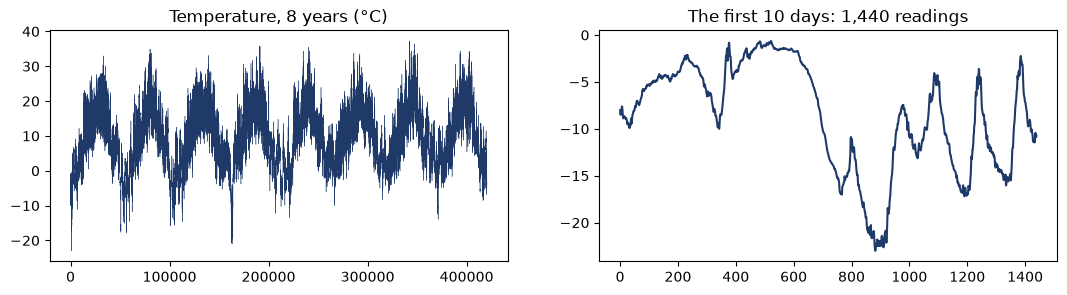

In [3]:
temperature = df["T (degC)"].to_numpy("float32")            # the target, in degrees Celsius
data = df.drop(columns="Date Time").to_numpy("float32")     # the 14 features (the temperature is one of them)

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
ax[0].plot(temperature, lw=0.3, color="#1f3a68"); ax[0].set_title("Temperature, 8 years (°C)")
ax[1].plot(temperature[:1440], color="#1f3a68"); ax[1].set_title("The first 10 days: 1,440 readings")
plt.show()

Split by time: the first half for training, the next quarter for validation, the last quarter for the test.

In [4]:
n_train = int(0.5 * len(data))
n_val = int(0.25 * len(data))
print("train", n_train, "| validation", n_val, "| test", len(data) - n_train - n_val)

train 210225 | validation 105112 | test 105114


## 2. Prepare it

The 14 columns live on very different scales: pressure is around 990, humidity around 80, wind speed around 2.
Each column is rescaled to mean 0 and standard deviation 1, with the mean and standard deviation of the
**training** half only. The target stays in degrees, so every error below is in degrees.

In [5]:
mean = data[:n_train].mean(axis=0)
std = data[:n_train].std(axis=0)
data = (data - mean) / std
pd.DataFrame({"mean": mean, "std": std}, index=df.columns[1:]).round(2).T

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
mean,988.75,8.83,282.910004,4.31,75.870003,13.15,9.19,3.95,5.81,9.3,1218.449951,2.15,3.56,176.440002
std,8.51,8.77,8.870000,7.08,16.629999,7.60,4.15,4.77,2.63,4.2,42.040001,1.53,2.32,85.849998


## 3. Cut it into windows

One sample: one reading per hour (every 6th row) for 5 days, so **120 time steps with 14 features**. Its target: the
temperature 24 hours after the window's last reading.

For a window that starts at row `s`, the readings are rows `s, s+6, ..., s+714`, and the target is row `s + 858`
(714 + 144: the last reading plus 24 hours of 10-minute rows).

**How far ahead.** In the language of the first notebook, Tx = 120 hours in and Ty = 1 value out: every forecast in
this notebook is **one step ahead**, made from real measurements. Multi-step (feeding forecasts back in) would need
forecasts of all 14 measurements, not only the temperature. Multi-output works with many inputs too: try Ty = 24
hours of temperature. One step, multi-step and multi-output have a video of their own, in theory and in Python.

In [6]:
RATE, LENGTH, AHEAD = 6, 120, 24                 # rows per hour, hours in, hours ahead
offsets = np.arange(LENGTH) * RATE               # 0, 6, ..., 714
delay = RATE * (LENGTH + AHEAD - 1)              # 858

def make_windows(start, end):
    """Windows that start in rows start ... end, each with the temperature 24 hours after its last reading."""
    starts = np.arange(start, min(end, len(data) - delay) - offsets[-1])
    X = data[starts[:, None] + offsets]          # (windows, 120, 14)
    y = temperature[starts + delay]
    return X, y

X_train, y_train = make_windows(0, n_train)
X_val, y_val = make_windows(n_train, n_train + n_val)
X_test, y_test = make_windows(n_train + n_val, len(data))
for name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name:10s} {X.shape}   {X.nbytes / 1e9:.1f} GB")

train      (209511, 120, 14)   1.4 GB
validation (104398, 120, 14)   0.7 GB
test       (103542, 120, 14)   0.7 GB


## 4. A baseline to beat

"In 24 hours it will be as warm as it is now." The temperature is column 1; undo the scaling to get degrees.

In [7]:
def naive(X, y):
    now = X[:, -1, 1] * std[1] + mean[1]         # the last reading's temperature, back in degrees
    return float(np.mean(np.abs(now - y)))

baseline = naive(X_test, y_test)
results = {"temperature now (baseline)": {"test": baseline, "best": baseline, "worst": baseline, "runs": 1, "validation": naive(X_val, y_val), "parameters": 0, "seconds per epoch": 0}}
print(f"validation {naive(X_val, y_val):.2f} degrees   test {naive(X_test, y_test):.2f} degrees")

validation 2.44 degrees   test 2.62 degrees


## 5. Build and train the models

One function trains any model the same way: mean squared error as the loss, the mean absolute error (in degrees) as
the number we read, 10 epochs, and the weights of the best validation epoch are the ones we test.

One training run is one draw: the starting weights are random, and the result moves with them. A few runs are not
enough to see that: for the dense network, three runs can land 0.2 degrees away from the middle of ten. So the five
fast models are trained `RUNS` = 10 times each, and the table shows the middle run with the best and the worst.
The two slow models are trained once.

In [8]:
class Clock(keras.callbacks.Callback):
    """Remembers how long each epoch took."""
    def on_train_begin(self, logs=None): self.seconds = []
    def on_epoch_begin(self, epoch, logs=None): self.start = time.time()
    def on_epoch_end(self, epoch, logs=None): self.seconds.append(time.time() - self.start)

def run(name, *hidden_layers, epochs=EPOCHS, runs=1):
    """Trains the model `runs` times from different starting weights and records the middle test error."""
    tests, histories, seconds = [], [], []
    for seed in range(runs):
        keras.utils.set_random_seed(seed)
        inputs = keras.Input(shape=(LENGTH, data.shape[-1]))
        x = inputs
        for layer in hidden_layers:
            x = type(layer).from_config(layer.get_config())(x)      # a fresh copy of the layer, with fresh starting weights
        model = keras.Model(inputs, layers.Dense(1)(x))
        model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
        if seed == 0:
            model.summary()
        clock = Clock()
        best = keras.callbacks.EarlyStopping(monitor="val_mae", patience=epochs, restore_best_weights=True)
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=256,
                            callbacks=[clock, best], verbose=2 if seed == 0 else 0)
        tests.append(model.evaluate(X_test, y_test, batch_size=1024, verbose=0)[1])
        histories.append(history.history); seconds.append(np.mean(clock.seconds[1:]))
        print(f"run {seed + 1} of {runs}: test error {tests[-1]:.2f} degrees")
    results[name] = {"test": float(np.median(tests)), "best": min(tests), "worst": max(tests), "runs": runs,
                     "validation": float(np.median([min(h["val_mae"]) for h in histories])),
                     "parameters": model.count_params(), "seconds per epoch": float(np.mean(seconds))}
    h = histories[0]
    plt.figure(figsize=(7, 2.6))
    plt.plot(h["mae"], "o-", label="training", color="#1f3a68")
    plt.plot(h["val_mae"], "o-", label="validation", color="#e07b39")
    plt.axhline(results["temperature now (baseline)"]["validation"], color="grey", ls=":", label="baseline (validation)")
    plt.title(f"{name}: test error {results[name]['test']:.2f} degrees (the first run's curves)"); plt.xlabel("epoch"); plt.ylabel("degrees"); plt.legend(); plt.show()

### A dense network

`Flatten` unrolls a window into one long row: 120 x 14 = 1,680 numbers. Every one of them gets its own weight in
every unit: 1,680 x 16 + 16 = **26,896** parameters in the first layer.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1680)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        26,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,913 (105.13 KB)

 Trainable params: 26,913 (105.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 4s - 5ms/step - loss: 15.1198 - mae: 3.0026 - val_loss: 13.5393 - val_mae: 2.9247
Epoch 2/10
819/819 - 2s - 2ms/step - loss: 10.2221 - mae: 2.5216 - val_loss: 12.9583 - val_mae: 2.8537
Epoch 3/10
819/819 - 2s - 2ms/step - loss: 9.3035 - mae: 2.4079 - val_loss: 12.2110 - val_mae: 2.7628
Epoch 4/10
819/819 - 2s - 2ms/step - loss: 8.7522 - mae: 2.3373 - val_loss: 12.0272 - val_mae: 2.7446
Epoch 5/10
819/819 - 2s - 3ms/step - loss: 8.4065 - mae: 2.2920 - val_loss: 12.3543 - val_mae: 2.7839
Epoch 6/10
819/819 - 2s - 3ms/step - loss: 8.0798 - mae: 2.2483 - val_loss: 12.1942 - val_mae: 2.7660
Epoch 7/10
819/819 - 2s - 3ms/step - loss: 7.7889 - mae: 2.2076 - val_loss: 12.1902 - val_mae: 2.7652
Epoch 8/10
819/819 - 3s - 3ms/step - loss: 7.5862 - mae: 2.1788 - val_loss: 11.9648 - val_mae: 2.7372
Epoch 9/10
819/819 - 2s - 3ms/step - loss: 7.4354 - mae: 2.1559 - val_loss: 11.9445 - val_mae: 2.7337
Epoch 10/10
819/819 - 2s - 3ms/step - loss: 7.2961 - mae: 2.1351 - val_loss: 11.

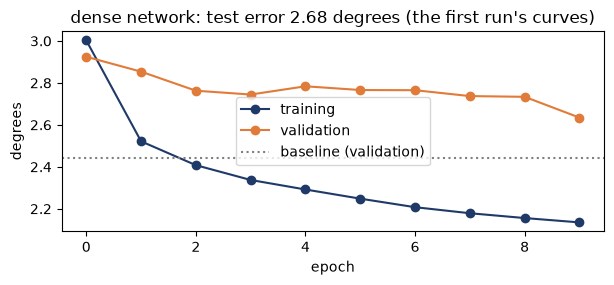

In [9]:
run("dense network", layers.Flatten(), layers.Dense(16, activation="relu"), runs=RUNS)

### A 1D convolution

A convolution slides a small window along the time axis and looks for the same pattern everywhere: 8 filters, each
24 hours wide over the 14 features (24 x 14 x 8 + 8 = 2,696 parameters). Pooling keeps the strongest response and
halves the length. It treats every position alike, which suits images better than a forecast, where the most recent
hours matter most.

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 97, 8)          │         2,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 48, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 37, 8)          │           776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 13, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 8)              │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,873 (15.13 KB)

 Trainable params: 3,873 (15.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 9s - 11ms/step - loss: 21.9576 - mae: 3.6563 - val_loss: 17.2135 - val_mae: 3.3178
Epoch 2/10
819/819 - 3s - 3ms/step - loss: 15.2968 - mae: 3.1111 - val_loss: 15.5434 - val_mae: 3.1412
Epoch 3/10
819/819 - 2s - 3ms/step - loss: 14.1651 - mae: 2.9876 - val_loss: 14.5321 - val_mae: 3.0218
Epoch 4/10
819/819 - 2s - 3ms/step - loss: 13.3596 - mae: 2.8984 - val_loss: 13.9049 - val_mae: 2.9431
Epoch 5/10
819/819 - 2s - 3ms/step - loss: 12.7462 - mae: 2.8290 - val_loss: 13.6535 - val_mae: 2.9069
Epoch 6/10
819/819 - 2s - 3ms/step - loss: 12.2418 - mae: 2.7728 - val_loss: 13.5734 - val_mae: 2.8916
Epoch 7/10
819/819 - 2s - 3ms/step - loss: 11.7999 - mae: 2.7227 - val_loss: 13.4787 - val_mae: 2.8739
Epoch 8/10
819/819 - 2s - 3ms/step - loss: 11.4111 - mae: 2.6773 - val_loss: 13.4116 - val_mae: 2.8647
Epoch 9/10
819/819 - 2s - 3ms/step - loss: 11.1026 - mae: 2.6416 - val_loss: 13.2807 - val_mae: 2.8472
Epoch 10/10
819/819 - 2s - 3ms/step - loss: 10.8225 - mae: 2.6078 - val_

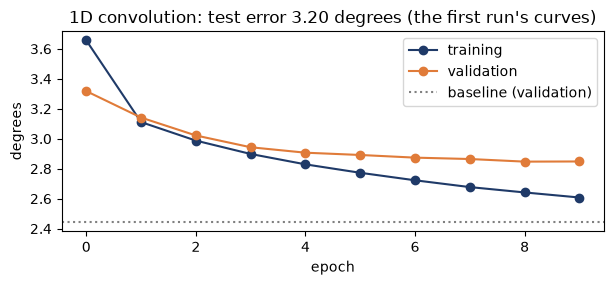

In [10]:
run("1D convolution",
    layers.Conv1D(8, 24, activation="relu"), layers.MaxPooling1D(2),
    layers.Conv1D(8, 12, activation="relu"), layers.MaxPooling1D(2),
    layers.Conv1D(8, 6, activation="relu"), layers.GlobalAveragePooling1D(), runs=RUNS)

### The simple RNN

14 x 16 weights on the input, 16 x 16 on the previous state, 16 biases: **496** parameters, shared by all 120 steps.

Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_20 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 17s - 21ms/step - loss: 49.4694 - mae: 5.1623 - val_loss: 13.3655 - val_mae: 2.7249
Epoch 2/10
819/819 - 14s - 17ms/step - loss: 11.4347 - mae: 2.6184 - val_loss: 9.4780 - val_mae: 2.3824
Epoch 3/10
819/819 - 14s - 17ms/step - loss: 10.4541 - mae: 2.5207 - val_loss: 9.1201 - val_mae: 2.3419
Epoch 4/10
819/819 - 14s - 17ms/step - loss: 10.2446 - mae: 2.4948 - val_loss: 8.9913 - val_mae: 2.3247
Epoch 5/10
819/819 - 14s - 17ms/step - loss: 10.1103 - mae: 2.4780 - val_loss: 8.9174 - val_mae: 2.3200
Epoch 6/10
819/819 - 14s - 17ms/step - loss: 9.9734 - mae: 2.4614 - val_loss: 8.8576 - val_mae: 2.3129
Epoch 7/10
819/819 - 14s - 17ms/step - loss: 9.8315 - mae: 2.4430 - val_loss: 8.8585 - val_mae: 2.3147
Epoch 8/10
819/819 - 14s - 17ms/step - loss: 9.7266 - mae: 2.4289 - val_loss: 8.9930 - val_mae: 2.3350
Epoch 9/10
819/819 - 14s - 17ms/step - loss: 9.6389 - mae: 2.4186 - val_loss: 9.0202 - val_mae: 2.3393
Epoch 10/10
819/819 - 15s - 18ms/step - loss: 9.5740 - mae: 2.4110 

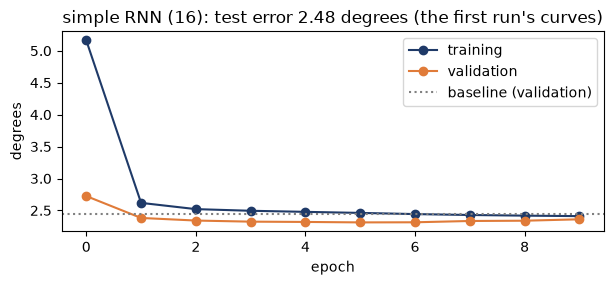

In [11]:
run("simple RNN (16)", layers.SimpleRNN(16), runs=RUNS)

### The LSTM

Three gates and a candidate, each with its own copy of those weights: 4 x 496 = **1,984**.

Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_30 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,001 (7.82 KB)

 Trainable params: 2,001 (7.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 8s - 10ms/step - loss: 41.3053 - mae: 4.6833 - val_loss: 12.8480 - val_mae: 2.7369
Epoch 2/10
819/819 - 7s - 9ms/step - loss: 10.9804 - mae: 2.5817 - val_loss: 9.5931 - val_mae: 2.4221
Epoch 3/10
819/819 - 7s - 9ms/step - loss: 9.9338 - mae: 2.4574 - val_loss: 9.6934 - val_mae: 2.4311
Epoch 4/10
819/819 - 7s - 9ms/step - loss: 9.5389 - mae: 2.4026 - val_loss: 9.6207 - val_mae: 2.4171
Epoch 5/10
819/819 - 8s - 9ms/step - loss: 9.2527 - mae: 2.3628 - val_loss: 10.0444 - val_mae: 2.4592
Epoch 6/10
819/819 - 7s - 9ms/step - loss: 9.0443 - mae: 2.3347 - val_loss: 9.9747 - val_mae: 2.4550
Epoch 7/10
819/819 - 7s - 9ms/step - loss: 8.8195 - mae: 2.3041 - val_loss: 10.2826 - val_mae: 2.4849
Epoch 8/10
819/819 - 7s - 8ms/step - loss: 8.6543 - mae: 2.2814 - val_loss: 10.5196 - val_mae: 2.5118
Epoch 9/10
819/819 - 7s - 8ms/step - loss: 8.4869 - mae: 2.2589 - val_loss: 10.5240 - val_mae: 2.5162
Epoch 10/10
819/819 - 7s - 9ms/step - loss: 8.3688 - mae: 2.2433 - val_loss: 10.127

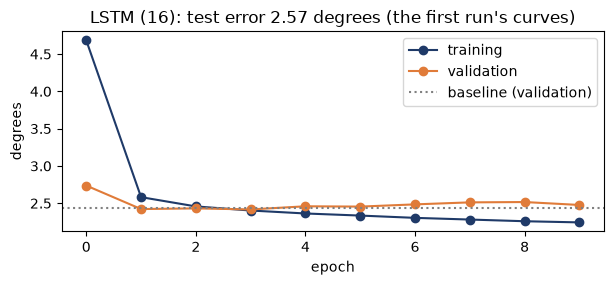

In [12]:
run("LSTM (16)", layers.LSTM(16), runs=RUNS)

### A bidirectional LSTM

Two LSTMs, one reading the window forward and one backward, their final states joined: 2 x 1,984 parameters. The
backward copy sees the most recent hours first and the oldest last.

Model: "functional_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_40 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 32)             │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,001 (15.63 KB)

 Trainable params: 4,001 (15.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 12s - 15ms/step - loss: 27.5196 - mae: 3.7531 - val_loss: 10.2751 - val_mae: 2.4756
Epoch 2/10
819/819 - 11s - 14ms/step - loss: 9.3301 - mae: 2.3827 - val_loss: 9.6771 - val_mae: 2.4192
Epoch 3/10
819/819 - 12s - 15ms/step - loss: 8.4431 - mae: 2.2711 - val_loss: 10.1934 - val_mae: 2.4840
Epoch 4/10
819/819 - 12s - 14ms/step - loss: 7.9835 - mae: 2.2130 - val_loss: 9.6987 - val_mae: 2.4200
Epoch 5/10
819/819 - 12s - 14ms/step - loss: 7.6149 - mae: 2.1643 - val_loss: 10.2740 - val_mae: 2.4909
Epoch 6/10
819/819 - 12s - 14ms/step - loss: 7.2899 - mae: 2.1191 - val_loss: 10.3910 - val_mae: 2.5124
Epoch 7/10
819/819 - 12s - 14ms/step - loss: 7.0236 - mae: 2.0800 - val_loss: 10.2986 - val_mae: 2.5021
Epoch 8/10
819/819 - 12s - 14ms/step - loss: 6.7860 - mae: 2.0439 - val_loss: 10.5471 - val_mae: 2.5169
Epoch 9/10
819/819 - 11s - 14ms/step - loss: 6.6462 - mae: 2.0234 - val_loss: 10.4914 - val_mae: 2.5193
Epoch 10/10
819/819 - 13s - 15ms/step - loss: 6.4417 - mae: 1.993

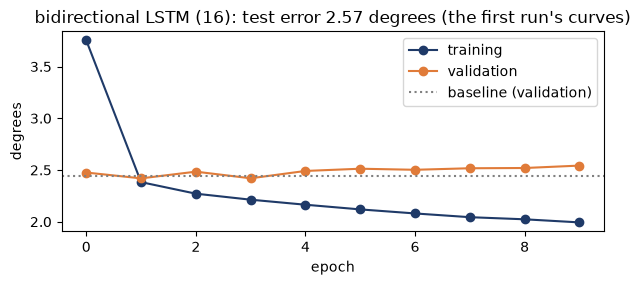

In [13]:
run("bidirectional LSTM (16)", layers.Bidirectional(layers.LSTM(16)), runs=RUNS)

### LSTM with recurrent dropout (slow)

A bigger LSTM (32 units) overfits, so it gets dropout. Inside the recurrent loop Keras uses `recurrent_dropout`:
one random mask per sequence, the same at every time step. The price: the layer can no longer use the fast GPU
routine for recurrent layers, and an epoch takes tens of times longer.

Model: "functional_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_50 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 271s - 330ms/step - loss: 28.4666 - mae: 3.9355 - val_loss: 9.6290 - val_mae: 2.4136
Epoch 2/10
819/819 - 264s - 322ms/step - loss: 14.9744 - mae: 3.0072 - val_loss: 9.1459 - val_mae: 2.3523
Epoch 3/10
819/819 - 265s - 324ms/step - loss: 14.2931 - mae: 2.9341 - val_loss: 9.0479 - val_mae: 2.3359
Epoch 4/10
819/819 - 270s - 330ms/step - loss: 13.8205 - mae: 2.8807 - val_loss: 8.8714 - val_mae: 2.3150
Epoch 5/10
819/819 - 261s - 319ms/step - loss: 13.3550 - mae: 2.8363 - val_loss: 8.8376 - val_mae: 2.3073
Epoch 6/10
819/819 - 263s - 321ms/step - loss: 13.0064 - mae: 2.8007 - val_loss: 8.8094 - val_mae: 2.2963
Epoch 7/10
819/819 - 344s - 420ms/step - loss: 12.5702 - mae: 2.7549 - val_loss: 8.7662 - val_mae: 2.2876
Epoch 8/10
819/819 - 312s - 381ms/step - loss: 12.4025 - mae: 2.7345 - val_loss: 8.7603 - val_mae: 2.2886
Epoch 9/10
819/819 - 266s - 325ms/step - loss: 12.1618 - mae: 2.7085 - val_loss: 8.7826 - val_mae: 2.2891
Epoch 10/10
819/819 - 262s - 320ms/step - loss

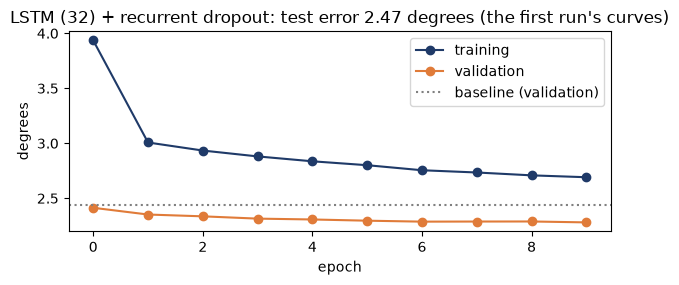

In [14]:
if RUN_SLOW:
    run("LSTM (32) + recurrent dropout", layers.LSTM(32, recurrent_dropout=0.25), layers.Dropout(0.5))

### Two stacked GRU layers with dropout (slower)

The GRU is a lighter cousin of the LSTM: two gates instead of three, and no separate cell state. The first layer
returns its state at every step (`return_sequences=True`) so that the second layer has a sequence to read.

Model: "functional_51"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_51 (InputLayer)     │ (None, 120, 14)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 120, 32)        │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,977 (42.88 KB)

 Trainable params: 10,977 (42.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
819/819 - 565s - 690ms/step - loss: 24.8776 - mae: 3.6976 - val_loss: 9.2373 - val_mae: 2.3494
Epoch 2/10
819/819 - 565s - 690ms/step - loss: 14.3185 - mae: 2.9305 - val_loss: 8.7203 - val_mae: 2.2863
Epoch 3/10
819/819 - 562s - 687ms/step - loss: 13.5426 - mae: 2.8530 - val_loss: 8.4855 - val_mae: 2.2585
Epoch 4/10
819/819 - 571s - 697ms/step - loss: 12.9403 - mae: 2.7905 - val_loss: 8.5650 - val_mae: 2.2685
Epoch 5/10
819/819 - 562s - 686ms/step - loss: 12.5896 - mae: 2.7514 - val_loss: 8.3247 - val_mae: 2.2346
Epoch 6/10
819/819 - 569s - 695ms/step - loss: 12.1055 - mae: 2.7013 - val_loss: 8.2355 - val_mae: 2.2197
Epoch 7/10
819/819 - 586s - 716ms/step - loss: 11.9058 - mae: 2.6778 - val_loss: 8.2897 - val_mae: 2.2260
Epoch 8/10
819/819 - 600s - 732ms/step - loss: 11.6252 - mae: 2.6488 - val_loss: 8.2212 - val_mae: 2.2220
Epoch 9/10
819/819 - 712s - 870ms/step - loss: 11.3863 - mae: 2.6201 - val_loss: 8.1669 - val_mae: 2.2133
Epoch 10/10
819/819 - 602s - 735ms/step - loss

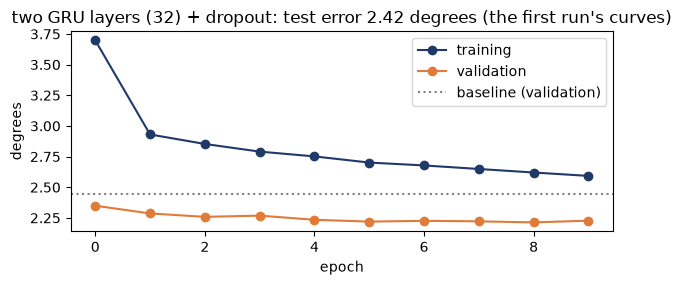

In [15]:
if RUN_SLOW:
    run("two GRU layers (32) + dropout",
        layers.GRU(32, recurrent_dropout=0.5, return_sequences=True),
        layers.GRU(32, recurrent_dropout=0.5), layers.Dropout(0.5))

## 6. Score them in real units

One table, one chart, everything in degrees on the test quarter. `test` is the middle run; `best` and `worst` show
how far apart the runs landed. Your numbers will differ a little from these and from the video: the starting weights
are random, and a GPU does not add numbers in the same order twice. The dense network and the convolution move the
most from run to run, and now and then a run of the convolution falls apart completely (it lands off the chart;
the `worst` column shows it). The simple RNN is the steadiest.

In [16]:
table = pd.DataFrame(results).T
table[["parameters", "runs"]] = table[["parameters", "runs"]].astype(int)
table.round(2)

,test,best,worst,runs,validation,parameters,seconds per epoch
temperature now (baseline),2.62,2.62,2.62,1,2.44,0,0.00
dense network,2.68,2.56,2.73,10,2.57,26913,2.18
1D convolution,3.20,2.99,6.10,10,2.99,3873,2.38
simple RNN (16),2.48,2.47,2.50,10,2.32,513,14.52
LSTM (16),2.57,2.49,2.70,10,2.40,2001,7.42
bidirectional LSTM (16),2.57,2.52,2.63,10,2.42,4001,11.76
LSTM (32) + recurrent dropout,2.47,2.47,2.47,1,2.28,6049,278.70
two GRU layers (32) + dropout,2.42,2.42,2.42,1,2.21,10977,592.19


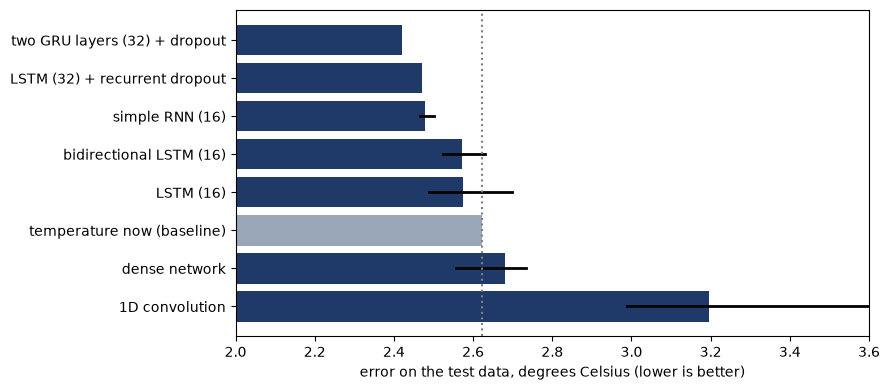

In [17]:
order = table.sort_values("test", ascending=False)
plt.figure(figsize=(9, 4))
plt.barh(order.index, order["test"], color=["#9aa7b8" if "baseline" in n else "#1f3a68" for n in order.index])
for name, lo, hi in zip(order.index, order["best"], order["worst"]):
    plt.plot([lo, hi], [name, name], color="black", lw=2)
plt.axvline(table.loc["temperature now (baseline)", "test"], color="grey", ls=":")
plt.xlim(2, 3.6); plt.xlabel("error on the test data, degrees Celsius (lower is better)"); plt.tight_layout(); plt.show()

## What this shows

- The baseline is hard to beat: a dense network with 27,000 weights ends up level with it at best, and the
  convolution well behind it.
- The recurrent models beat it, with a few hundred to a few thousand weights. They read the window in order and
  reuse the same weights at every hour. Only the simple RNN beats it in every single run.
- The LSTM does not beat the simple RNN here. This task rewards the last day or two, not a long memory.
- Reading the window backward as well does not help a forecast.
- Regularized, larger recurrent models gain a little more, and cost far more time.
- The gains are tenths of a degree. Weather 24 hours ahead from one station is a hard problem.

## Try it yourself, with a coding assistant

- "Forecast 12 hours ahead instead of 24." (Change `AHEAD`.)
- "Use only the temperature column as input, and compare."
- "Add a GRU with 16 units and no dropout to the table."
- "Rewrite this for PyTorch." or "Update this for the current version of Keras."

Then check what you get back: the shapes of the windows, that the split is by time, that the baseline is still in
the table, and that the test quarter is only used for the final score.